Masking Airglow Emission
=========================

#### Introduction

Airglow is faint natural emission from the Earth's upper atmosphere, produced by various chemical and physical processes. In near-infrared spectroscopy, airglow is dominated by emission lines from hydroxyl (OH) molecules, with additional contributions from molecular oxygen (O\ :sub:`2` \) and other species.

The intensity of airglow varies with time and atmospheric conditions, making it difficult to predict and subtract accurately (e.g., Kawahara et al. 2012; Hart 2019).

When observing faint objects, such as brown dwarfs, with IRD, airglow emission lines can contaminate the observed spectra. This contamination is less significant in REACH observations because of the smaller fiber aperture, which collects less background emission from the sky.

One approach to mitigating this contamination is to mask the wavelength regions affected by airglow emission.

#### Airglow Line List

Comparisons with IRD observations have shown that the airglow line list provided by Oliva et al. (2015) gives the best agreement with the observed emission features among the line lists examined (see Kasagi's doctoral thesis).

The Oliva et al. (2015) line list covers the Y, J, and H bands in the near-infrared and includes emission lines identified as:

- OH: Hydroxyl emission, one of the dominant sources of near-infrared airglow.

- O\ :sub:`2` \: Molecular oxygen emission from the Earth's atmosphere.

- Unknown: Emission features whose molecular or atomic origins have not been identified.

PyIRD uses the Oliva et al. (2015) line list to identify wavelength regions potentially contaminated by airglow. The mask_airglow function masks a region of :math:`\pm 0.035` nm (by default) around each listed line center by replacing the corresponding flux values with NaN.

This allows users to exclude airglow-contaminated regions from subsequent spectral analysis.

- :ref:`step1`
- :ref:`step2`
- :ref:`check`

.. _step1: 

## Step 1: Settings

Set the data path and analysis parameters, including:
- spectral band (e.g., H band)
- fiber (mmf1 or mmf2)
- prefix of the 1D spectrum files

The following example shows the case of analyzing normalized H-band spectra (nw41511_m2.dat).

In [1]:
from pyird.utils import irdstream
import pathlib

#--------SETTINGS--------#
basedir = pathlib.Path('~/pyird/data/20210317/').expanduser()

band = 'h' #'h' or 'y'
mmf = 'mmf2' #'mmf1' (comb fiber) or 'mmf2' (star fiber)

rawdir = basedir/'reduc/'
anadir_1d = basedir/'reduc_1d/'

# last 5 digits of FITS file numbers: [start, end file number]
target_id = [41510, 41511] # target image
target_prefix = "nw"
target_name = "G196-3B"
#-------------------------#

.. _step2: 

## Step 2: Mask Airglow Emission

The data to be analyzed can be specified using the `Stream1D' class:

In [2]:
target_1d = irdstream.Stream1D(streamid=target_name, 
                               rawdir=rawdir, 
                               anadir=anadir_1d, 
                               fitsid=list(range(target_id[0], target_id[-1], 2)),
                               prefix=target_prefix, # w or nw
                               extension=f"_m{mmf[-1]}", # fiber
                               inst="IRD",
                               band=band)
target_1d.info = True

fitsid is incremented.
Processing h band
Processing fitsid: [41511]


You can mask wavelength regions affected by airglow using the `mask_airglow` function.

Setting `plot=True` displays a comparison of the spectra before and after masking, allowing you to visually inspect the results.

/Users/yuikasagi/git/pyird/src/pyird/cleaning/remove_airglow.py:13: SyntaxWarning: invalid escape sequence '\s'
  oliva_tb1 = pd.read_csv(file_tb1, sep='\s+', names=['lambda1', 'Iden1', 'lambda2', 'Iden2', 'Flux'])
/Users/yuikasagi/git/pyird/src/pyird/cleaning/remove_airglow.py:14: SyntaxWarning: invalid escape sequence '\s'
  oliva_tb2 = pd.read_csv(file_tb2, sep='\s+', names=['lambda', 'Iden', 'Flux', 'q_Flux'])
/Users/yuikasagi/git/pyird/src/pyird/cleaning/remove_airglow.py:74: SyntaxWarning: invalid escape sequence '\s'
  df_obs = pd.read_csv(file, sep="\s+", names=["wav","flux","uncertainty"])


[STEP] Masking airglow lines...


  0%|          | 0/1 [00:00<?, ?it/s]

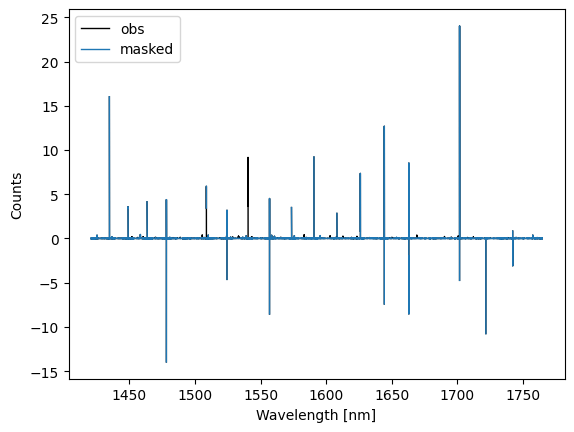

100%|██████████| 1/1 [00:00<00:00,  3.07it/s]

masking airglow: output = nw41511_m2_ohmasked.dat


In [3]:
# airglow mask
target_1d.mask_airglow(plot=True)

The masked spectrum is automatically saved as a new file, leaving the original spectrum unchanged.

In this example, the output file `nw41511_m2_ohmasked.dat` is saved in the `anadir_1d` directory.

.. _check: 

## Check the Masked Spectrum

Let's take a closer look at the spectrum before and after airglow masking.

In [4]:
import pandas as pd

read_args = dict(sep='\s+', header=None, names=["wav", "order", "flux", "snr", "uncertainties"])
df_nw = pd.read_csv(rawdir / f'{target_prefix}{target_1d.fitsid[0]}_m{mmf[-1]}.dat', **read_args)
df_nw_ohmasked = pd.read_csv(anadir_1d / f'{target_prefix}{target_1d.fitsid[0]}{target_1d.extension}.dat', **read_args)

orders = df_nw["order"].unique()

<>:3: SyntaxWarning: invalid escape sequence '\s'
<>:3: SyntaxWarning: invalid escape sequence '\s'
/var/folders/sb/rxwbk6kd4gldqpdvzxnhq4xm0000gn/T/ipykernel_88950/1145652374.py:3: SyntaxWarning: invalid escape sequence '\s'
  read_args = dict(sep='\s+', header=None, names=["wav", "order", "flux", "snr", "uncertainties"])


In [5]:
from importlib.resources import files

path_oliva_table1 = files("pyird").joinpath("data", "Oliva+15_table1.dat")
path_oliva_table2 = files("pyird").joinpath("data", "Oliva+15_table2.dat")

df_oliva_table1 = pd.read_csv(path_oliva_table1, sep='\s+', names=['lambda1','Iden1','lambda2','Iden2','Flux'])
df_oliva_table2 = pd.read_csv(path_oliva_table2, sep='\s+', names=['lambda','Iden','Flux','q_Flux'])

<>:6: SyntaxWarning: invalid escape sequence '\s'
<>:7: SyntaxWarning: invalid escape sequence '\s'
<>:6: SyntaxWarning: invalid escape sequence '\s'
<>:7: SyntaxWarning: invalid escape sequence '\s'
/var/folders/sb/rxwbk6kd4gldqpdvzxnhq4xm0000gn/T/ipykernel_88950/2475689404.py:6: SyntaxWarning: invalid escape sequence '\s'
  df_oliva_table1 = pd.read_csv(path_oliva_table1, sep='\s+', names=['lambda1','Iden1','lambda2','Iden2','Flux'])
/var/folders/sb/rxwbk6kd4gldqpdvzxnhq4xm0000gn/T/ipykernel_88950/2475689404.py:7: SyntaxWarning: invalid escape sequence '\s'
  df_oliva_table2 = pd.read_csv(path_oliva_table2, sep='\s+', names=['lambda','Iden','Flux','q_Flux'])


/var/folders/sb/rxwbk6kd4gldqpdvzxnhq4xm0000gn/T/ipykernel_88950/3267120768.py:36: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  axs[1].legend(loc='upper right')


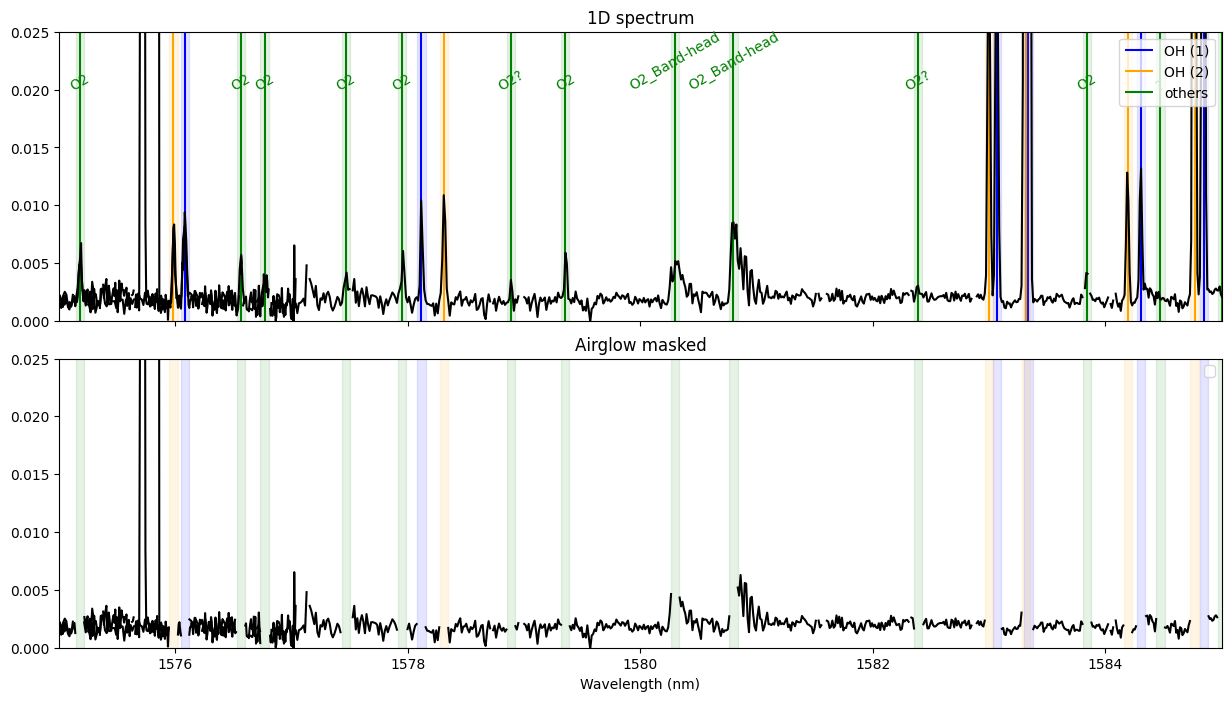

In [6]:
import matplotlib.pyplot as plt

fig, axs = plt.subplots(2, 1, figsize=(15,8), sharex=True, sharey=True, gridspec_kw={'hspace': 0.13})

scale = 1
for j, ax in enumerate(axs):
    if j==0:
        ax.vlines(df_oliva_table1['lambda1']*1e-1,0,df_oliva_table1['Flux']*scale,color='blue',label='OH (1)',zorder=1)
        ax.vlines(df_oliva_table1['lambda2']*1e-1,0,df_oliva_table1['Flux']*scale,color='orange',label='OH (2)',zorder=1)
        ax.vlines(df_oliva_table2['lambda']*1e-1,0,df_oliva_table2['Flux']*scale,color='green',label='others',zorder=1)

    width=0.035
    for i in range(len(df_oliva_table1)):
        ax.axvspan(df_oliva_table1['lambda1'][i]*1e-1-width,df_oliva_table1['lambda1'][i]*1e-1+width,0,df_oliva_table1['Flux'][i],color='blue',alpha=0.1)
        ax.axvspan(df_oliva_table1['lambda2'][i]*1e-1-width,df_oliva_table1['lambda2'][i]*1e-1+width,0,df_oliva_table1['Flux'][i],color='orange',alpha=0.1)
    for i in range(len(df_oliva_table2)):
        ax.axvspan(df_oliva_table2['lambda'][i]*1e-1-width,df_oliva_table2['lambda'][i]*1e-1+width,0,df_oliva_table2['Flux'][i],color='green',alpha=0.1)

    if j==0:
        wmin, wmax = 1575, 1585
        df_oliva_table2_lim = df_oliva_table2[(wmin<=df_oliva_table2['lambda']*1e-1) & (df_oliva_table2['lambda']*1e-1<=wmax)]
        for i in range(len(df_oliva_table2_lim)):
            ax.text(df_oliva_table2_lim['lambda'].values[i]*1e-1, 0.02, df_oliva_table2_lim['Iden'].values[i], ha='center', color='green', size=10, rotation=30)


for ord in orders:
    df_nw_ord = df_nw[df_nw['order']==ord]
    df_nw_ohmasked_ord = df_nw_ohmasked[df_nw_ohmasked['order']==ord]

    axs[0].plot(df_nw_ord['wav'], df_nw_ord['flux'], color='k', alpha=1)#, label='1D spectrum' if ord==orders[0] else None)
    axs[1].plot(df_nw_ohmasked_ord['wav'], df_nw_ohmasked_ord['flux'], color='k', alpha=1)#, label='Airglow masked' if ord==orders[0] else None)

axs[0].set(title="1D spectrum")
axs[1].set(title="Airglow masked")
axs[0].legend(loc='upper right')
axs[1].legend(loc='upper right')
axs[0].set(ylim=(0, 0.025), xlim=(1575., 1585.), )
axs[1].set(xlabel='Wavelength (nm)')
plt.show()

#### Upper panel: Before masking

The upper panel shows the original spectrum of a brown dwarf, together with the wavelengths of airglow emission lines from Oliva et al. (2015).

The vertical lines indicate the central wavelengths of the airglow features:

- Blue and yellow lines: OH emission lines.

- Green lines: Other emission features, including O\ :sub:`2` \ and unidentified lines.

The lightly shaded regions around each line indicate the wavelength intervals to be masked, extending :math:`\pm 0.035` nm from the line center. The shading colors correspond to those of the vertical lines.

#### Lower panel: After masking

The lower panel shows the spectrum after applying the airglow mask.

Most of the prominent airglow emission features have been successfully removed from the spectrum.

However, some features remain, including the bandhead near 1580 nm and spurious emission-like features associated with bad pixels. These are not necessarily covered by the airglow line list and therefore remain unaffected by the masking procedure.

**Note**: Airglow masking removes the affected wavelength regions from the analysis rather than reconstructing the intrinsic spectrum. Additional processing may be required to handle residual artifacts or other sources of contamination.

#### References

- Kawahara et al., 2012, ApJ 758.1, 13
- Hart, 2019, PASP 131.995
- Oliva et al., 2015, A \& A 581, A47
- [Kasagi (Ph.D. thesis)](https://ir.soken.ac.jp/records/2000133)